In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df1 = pd.read_csv('product_category_name_translation.csv')
df2 = pd.read_csv('olist_order_payments_dataset.csv')
df3 = pd.read_csv('olist_products_dataset.csv')
df4 = pd.read_csv('olist_order_items_dataset.csv')

# Remocao de nulos
df3 = df3.dropna()

# Conversao de tipos
df3['product_photos_qty'] = df3['product_photos_qty'].astype('int64')
df3['product_name_lenght'] = df3['product_name_lenght'].astype('int64')
df3['product_description_lenght'] = df3['product_description_lenght'].astype('int64')
#conversão para tempo
df4['shipping_limit_date'] = df4['shipping_limit_date'].astype('datetime64[ms]')

#correção de outliers
# Remocao de parcelas zeradas
df2 = df2[df2['payment_installments'] > 0]
# Correcao de peso zerado pela mediana
df3.loc[df3['product_weight_g'] == 0, 'product_weight_g'] = df3['product_weight_g'].median()


Divide a base em 4 grupos de produtos com base nas medianas (ou limites IQR), identificando gargalos e oportunidades de venda.
- Baixo Preço + Baixo Frete: Produtos de entrada / Venda rápida.
- Baixo Preço + Alto Frete: Barreira de conversão (o frete custa quase o preço do produto).
- Alto Preço + Baixo Frete: Oferta Premium atraente (margeia bem e o frete não dói no bolso).
- Alto Preço + Alto Frete: Produtos volumosos/pesados de alto valor.

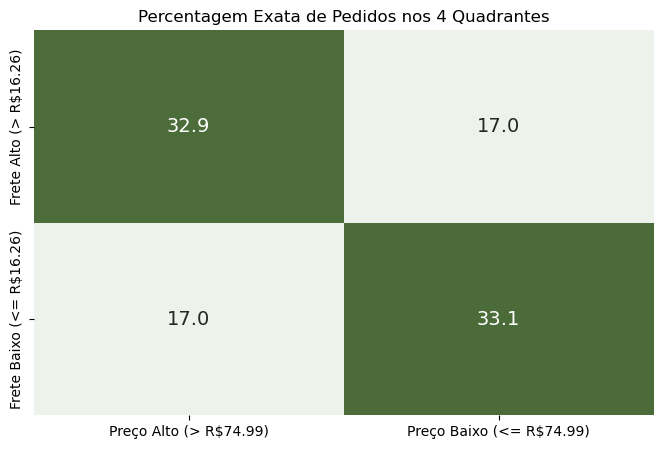

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df4['Grupo_Preco'] = df4['price'].apply(
    lambda x: 'Preço Alto (> R$74.99)' if x > 74.99 else 'Preço Baixo (<= R$74.99)'
)
df4['Grupo_Frete'] = df4['freight_value'].apply(
    lambda y: 'Frete Alto (> R$16.26)' if y > 16.26 else 'Frete Baixo (<= R$16.26)'
)

matriz_4grupos = (
    pd.crosstab(df4['Grupo_Frete'], df4['Grupo_Preco'], normalize='all') * 100
)

cmap = sns.light_palette('#4B6B38', as_cmap=True)

plt.figure(figsize=(8, 5))
sns.heatmap(
    matriz_4grupos,
    annot=True,
    fmt='.1f',
    cmap=cmap,
    cbar=False,
    annot_kws={'size': 14},
)

plt.title('Percentagem Exata de Pedidos nos 4 Quadrantes')
plt.xlabel('')
plt.ylabel('')
plt.show()

Gráfico de barras para facilitar a visualização

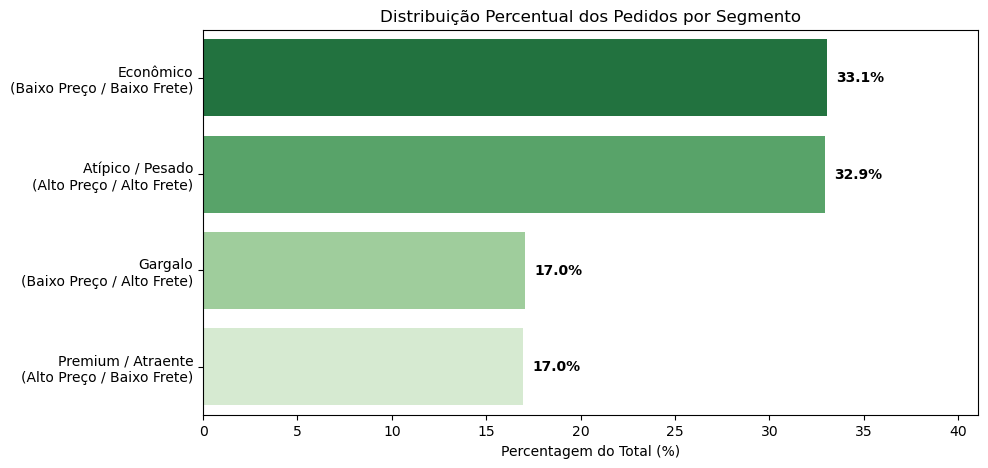

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def classificar_quadrante(row):
    if row['price'] <= 74.99 and row['freight_value'] <= 16.26:
        return 'Econômico\n(Baixo Preço / Baixo Frete)'
    elif row['price'] <= 74.99 and row['freight_value'] > 16.26:
        return 'Gargalo\n(Baixo Preço / Alto Frete)'
    elif row['price'] > 74.99 and row['freight_value'] <= 16.26:
        return 'Premium / Atraente\n(Alto Preço / Baixo Frete)'
    else:
        return 'Atípico / Pesado\n(Alto Preço / Alto Frete)'

df4['segmento_oferta'] = df4.apply(classificar_quadrante, axis=1)

contagem_segmento = df4['segmento_oferta'].value_counts(normalize=True) * 100

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=contagem_segmento.values,
    y=contagem_segmento.index,
    hue=contagem_segmento.index,
    palette='Greens_r',
    legend=False
)

for i, v in enumerate(contagem_segmento.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontweight='bold')

plt.title('Distribuição Percentual dos Pedidos por Segmento')
plt.xlabel('Percentagem do Total (%)')
plt.ylabel('')
plt.xlim(0, max(contagem_segmento.values) + 8)
plt.show()

Representação do frete por preço: Mostra quanto o frete representa percentualmente em relação ao valor do produto

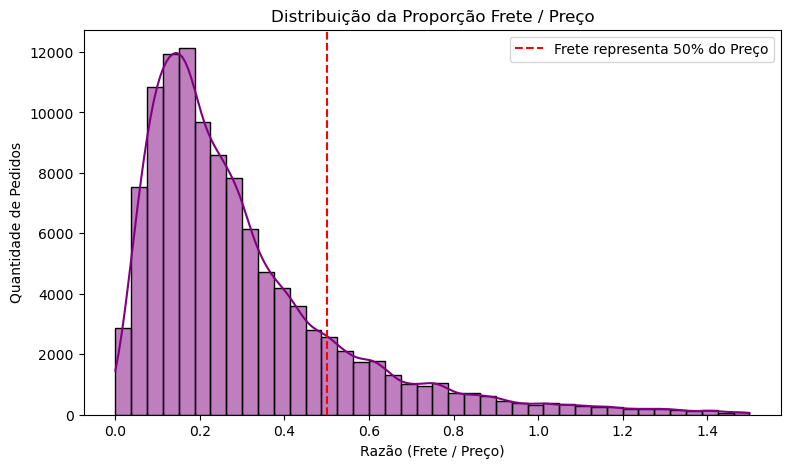

In [ ]:
# Criando a métrica de proporção
df4['freight_ratio'] = df4['freight_value'] / df4['price']

plt.figure(figsize=(9, 5))
sns.histplot(df4[df4['freight_ratio'] <= 1.5]['freight_ratio'], kde=True, color='purple', bins=40)
plt.axvline(0.5, color='red', linestyle='--', label='Frete representa 50% do Preço')
plt.title('Distribuição da Proporção Frete / Preço')
plt.xlabel('Razão (Frete / Preço)')
plt.ylabel('Quantidade de Pedidos')
plt.legend()
plt.show()

Top Categorias de Produtos no Segmento "Gargalo"

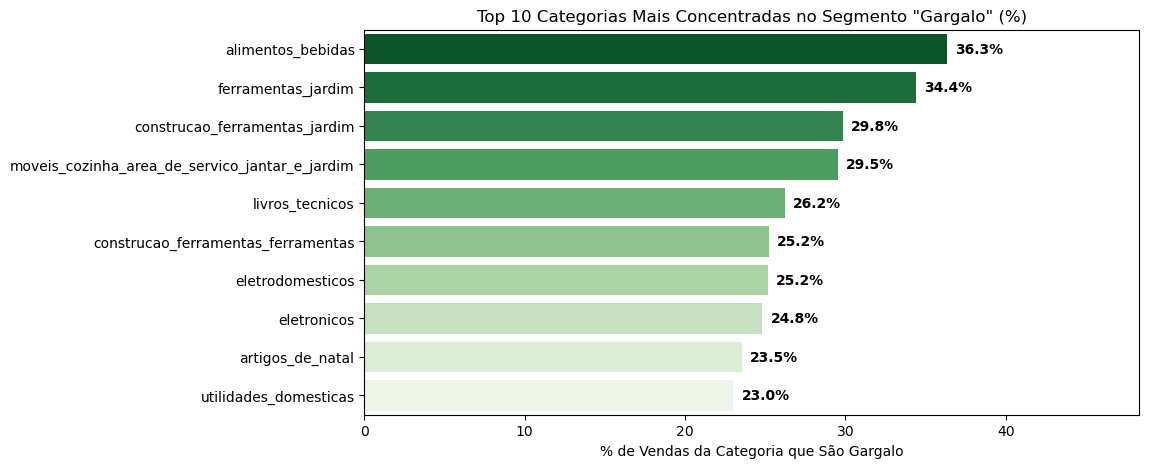

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cruzar dados para obter a categoria
df4_completo = df4.merge(
    df3[['product_id', 'product_category_name']], on='product_id', how='left'
)

# 2. Filtrar categorias com volume relevante (> 100 vendas totais)
volume_total = df4_completo['product_category_name'].value_counts()
cat_relevantes = volume_total[volume_total > 100].index

# 3. Calcular a % de vendas no segmento Gargalo para cada categoria
vendas_gargalo = df4_completo[
    df4_completo['segmento_oferta'].str.contains('Gargalo', na=False)
]['product_category_name'].value_counts()

propensao_gargalo = (
    (vendas_gargalo / volume_total * 100)
    .loc[cat_relevantes]
    .dropna()
    .sort_values(ascending=False)
    .head(10)
)

# 4. Exibir o gráfico de concentração relativa
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=propensao_gargalo.values,
    y=propensao_gargalo.index,
    hue=propensao_gargalo.index,
    palette='Greens_r',
    legend=False,
)

for i, v in enumerate(propensao_gargalo.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontweight='bold')

plt.title('Top 10 Categorias Mais Concentradas no Segmento "Gargalo" (%)')
plt.xlabel('% de Vendas da Categoria que São Gargalo')
plt.ylabel('')
plt.xlim(0, max(propensao_gargalo.values) + 12)
plt.show()

Top Categorias de Produtos no Segmento "Premium"

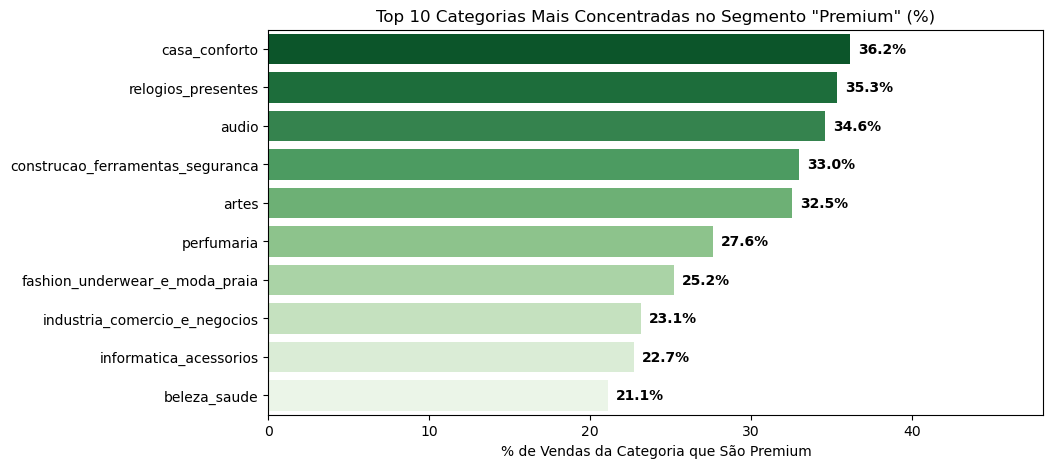

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cruzar dados de categoria
df4_completo = df4.merge(
    df3[['product_id', 'product_category_name']], on='product_id', how='left'
)

# 2. Filtrar apenas categorias com volume mínimo relevante (ex: mais de 100 vendas totais)
volume_total = df4_completo['product_category_name'].value_counts()
cat_relevantes = volume_total[volume_total > 100].index

# 3. Calcular a % de vendas no segmento Premium para cada categoria
vendas_premium = df4_completo[
    df4_completo['segmento_oferta'].str.contains('Premium', na=False)
]['product_category_name'].value_counts()

propensao_premium = (vendas_premium / volume_total * 100).loc[cat_relevantes].dropna().sort_values(ascending=False).head(10)

# 4. Gerar o gráfico de concentração relativa
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=propensao_premium.values,
    y=propensao_premium.index,
    hue=propensao_premium.index,
    palette='Greens_r',
    legend=False
)

for i, v in enumerate(propensao_premium.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontweight='bold')

plt.title('Top 10 Categorias Mais Concentradas no Segmento "Premium" (%)')
plt.xlabel('% de Vendas da Categoria que São Premium')
plt.ylabel('')
plt.xlim(0, max(propensao_premium.values) + 12)
plt.show()

# 🚀 SPRINT: MODELAGEM ANALÍTICA E RECOMENDAÇÕES ESTRATÉGICAS
## Segmentação de Ofertas: Classificação dos Produtos Combinando Preço do Item e Custo do Frete

---

### 1. Contexto e Objetivos da Sprint
A viabilidade comercial de um produto no e-commerce depende criticamente da **percepção de valor combinada entre o Preço do Item e o Custo do Frete**. O consumidor não decide sua compra isolando o valor do produto na vitrine, mas sim avaliando o **desembolso total no checkout**:
* **Baixo Preço + Alto Frete (Gargalo)**: O frete representa quase o valor do produto, gerando aversão psicológica e abandono imediato de carrinho.
* **Alto Preço + Baixo Frete (Premium Atraente)**: O custo de envio é imperceptível diante do valor agregado do item, propiciando altíssima conversão e rentabilidade.
* **Baixo Preço + Baixo Frete (Econômico)**: Motor de giro rápido e atração de novos clientes para a base.
* **Alto Preço + Alto Frete (Carga Pesada / Atípico)**: Produtos volumosos de alto ticket que exigem condições especiais de parcelamento e logística.

Com a **etapa preliminar de limpeza e exploração inicial já concluída** (células 0 a 10), esta Sprint tem como foco:
1. **Modelagem Analítica Multidimensional dos Quadrantes de Oferta**: Decompor o volume de vendas, faturamento bruto (GMV), ticket médio, peso médio e o perfil de financiamento (parcelamento) de cada segmento.
2. **Modelagem Não Supervisionada de Machine Learning (Clusterização K-Means)**: Descobrir os agrupamentos naturais de ofertas no espaço contínuo de Preço, Frete e Razão Frete/Preço, validando o número ótimo de clusters pelo Método do Cotovelo (Elbow Method).
3. **Mapeamento de Categorias Críticas e Formas de Pagamento**: Identificar quais categorias estão aprisionadas no "Gargalo" versus líderes no "Premium", e como o parcelamento no cartão atua como mitigador de atrito logístico.
4. **Recomendações Prescritivas e Playbook de Ação por Segmento**: Desenvolver estratégias práticas de precificação, bundling de produtos, subsídios inteligentes e governança comercial para maximizar as vendas e a rentabilidade da plataforma.

---
### 📊 Etapa 1: Diagnóstico Financeiro e Decomposição dos Segmentos de Oferta

Nesta etapa, consolidamos a classificação por quadrantes realizada na exploração inicial com os dados de pagamentos (`df2`) e características físicas dos produtos (`df3`), gerando um painel executivo com:
* **Volume de Demanda** (quantidade de itens e % do total)
* **Faturamento Bruto Gerado (GMV Total)** e concentração percentual da receita
* **Ticket Médio de Preço** vs **Custo Médio de Frete**
* **Razão Frete/Preço Mediana** (impacto proporcional no bolso do comprador)
* **Comportamento de Parcelamento Médio** (`payment_installments`)
* **Peso Médio dos Produtos** em cada segmento

📈 DIAGNÓSTICO FINANCEIRO E OPERACIONAL DOS SEGMENTOS DE OFERTA
                               segmento_oferta  total_itens  pct_volume  gmv_total   pct_gmv  ticket_medio_preco  frete_medio  razao_frete_mediana
   Atípico / Pesado\n(Alto Preço / Alto Frete)        37099   32.932978 8550981.82 62.913523          230.490898    30.675217            16.756549
Premium / Atraente\n(Alto Preço / Baixo Frete)        19110   16.964048 2736393.06 20.132908          143.191683    12.664598            10.489209
        Econômico\n(Baixo Preço / Baixo Frete)        37240   33.058145 1437167.46 10.573905           38.592037    12.008654            31.340298
           Gargalo\n(Baixo Preço / Alto Frete)        19201   17.044829  867101.36  6.379665           45.159177    22.116916            46.416667


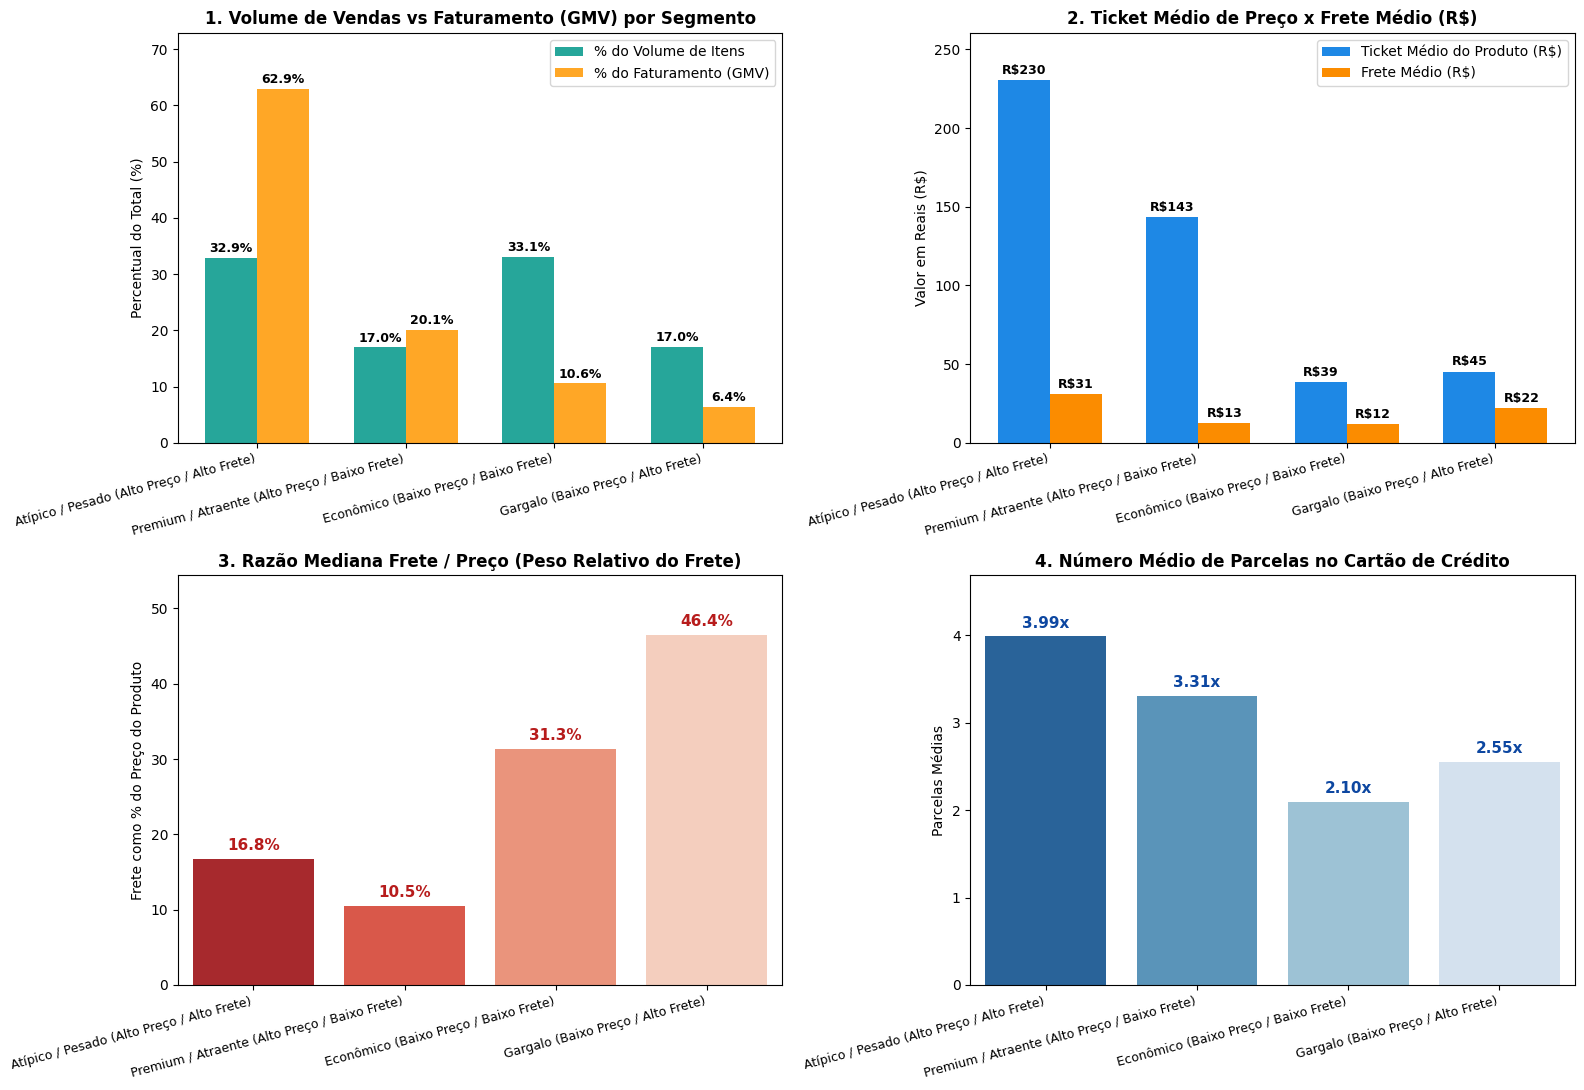

In [12]:
# 1. Enriquecimento dos Itens com Pagamentos e Características Físicas
# Agregação de pagamentos por pedido para obter o parcelamento médio
df2_pedidos = df2.groupby('order_id').agg({
    'payment_installments': 'mean',
    'payment_value': 'sum'
}).reset_index()

# Integração completa
df_ofertas = df4.merge(df2_pedidos, on='order_id', how='left')
df_ofertas = df_ofertas.merge(
    df3[['product_id', 'product_category_name', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']],
    on='product_id',
    how='left'
)

# 2. Tabela Analítica de Performance dos 4 Segmentos de Oferta
tabela_segmentos = df_ofertas.groupby('segmento_oferta').agg(
    total_itens=('order_id', 'count'),
    pct_volume=('order_id', lambda x: len(x) / len(df_ofertas) * 100),
    gmv_total=('price', 'sum'),
    ticket_medio_preco=('price', 'mean'),
    frete_medio=('freight_value', 'mean'),
    razao_frete_mediana=('freight_ratio', lambda x: x.median() * 100),
    parcelas_media=('payment_installments', 'mean'),
    peso_medio_g=('product_weight_g', 'mean')
).reset_index()

# Calcular percentual do GMV total
gmv_global = tabela_segmentos['gmv_total'].sum()
tabela_segmentos['pct_gmv'] = (tabela_segmentos['gmv_total'] / gmv_global) * 100

# Ordenar por GMV decrescente
tabela_segmentos = tabela_segmentos.sort_values(by='gmv_total', ascending=False).reset_index(drop=True)

print("="*85)
print("📈 DIAGNÓSTICO FINANCEIRO E OPERACIONAL DOS SEGMENTOS DE OFERTA")
print("="*85)
print(tabela_segmentos[['segmento_oferta', 'total_itens', 'pct_volume', 'gmv_total', 'pct_gmv', 'ticket_medio_preco', 'frete_medio', 'razao_frete_mediana']].to_string(index=False))
print("="*85)

# 3. Painel Gráfico 2x2: Análise Comparativa dos Segmentos
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Nomes curtos para os eixos
rotulos_curtos = [s.replace('\n', ' ') for s in tabela_segmentos['segmento_oferta']]
x_pos = np.arange(len(tabela_segmentos))
w = 0.35

# Gráfico 1: Volume de Pedidos vs Faturamento (GMV)
axes[0, 0].bar(x_pos - w/2, tabela_segmentos['pct_volume'], width=w, label='% do Volume de Itens', color='#26A69A')
axes[0, 0].bar(x_pos + w/2, tabela_segmentos['pct_gmv'], width=w, label='% do Faturamento (GMV)', color='#FFA726')
for i in range(len(tabela_segmentos)):
    axes[0, 0].text(x_pos[i] - w/2, tabela_segmentos['pct_volume'][i] + 1, f"{tabela_segmentos['pct_volume'][i]:.1f}%", ha='center', fontweight='bold', fontsize=9)
    axes[0, 0].text(x_pos[i] + w/2, tabela_segmentos['pct_gmv'][i] + 1, f"{tabela_segmentos['pct_gmv'][i]:.1f}%", ha='center', fontweight='bold', fontsize=9)
axes[0, 0].set_title('1. Volume de Vendas vs Faturamento (GMV) por Segmento', fontweight='bold')
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(rotulos_curtos, rotation=15, ha='right', fontsize=9)
axes[0, 0].set_ylabel('Percentual do Total (%)')
axes[0, 0].set_ylim(0, max(tabela_segmentos['pct_gmv']) + 10)
axes[0, 0].legend()

# Gráfico 2: Ticket Médio de Preço vs Custo Médio de Frete
axes[0, 1].bar(x_pos - w/2, tabela_segmentos['ticket_medio_preco'], width=w, label='Ticket Médio do Produto (R$)', color='#1E88E5')
axes[0, 1].bar(x_pos + w/2, tabela_segmentos['frete_medio'], width=w, label='Frete Médio (R$)', color='#FB8C00')
for i in range(len(tabela_segmentos)):
    axes[0, 1].text(x_pos[i] - w/2, tabela_segmentos['ticket_medio_preco'][i] + 4, f"R${tabela_segmentos['ticket_medio_preco'][i]:.0f}", ha='center', fontweight='bold', fontsize=9)
    axes[0, 1].text(x_pos[i] + w/2, tabela_segmentos['frete_medio'][i] + 4, f"R${tabela_segmentos['frete_medio'][i]:.0f}", ha='center', fontweight='bold', fontsize=9)
axes[0, 1].set_title('2. Ticket Médio de Preço x Frete Médio (R$)', fontweight='bold')
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(rotulos_curtos, rotation=15, ha='right', fontsize=9)
axes[0, 1].set_ylabel('Valor em Reais (R$)')
axes[0, 1].set_ylim(0, max(tabela_segmentos['ticket_medio_preco']) + 30)
axes[0, 1].legend()

# Gráfico 3: Razão Mediana Frete / Preço (%)
sns.barplot(
    data=tabela_segmentos, x='segmento_oferta', y='razao_frete_mediana',
    palette='Reds_r', hue='segmento_oferta', legend=False, ax=axes[1, 0]
)
for i, v in enumerate(tabela_segmentos['razao_frete_mediana']):
    axes[1, 0].text(i, v + 1.2, f"{v:.1f}%", ha='center', fontweight='bold', color='#B71C1C', fontsize=11)
axes[1, 0].set_title('3. Razão Mediana Frete / Preço (Peso Relativo do Frete)', fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Frete como % do Preço do Produto')
axes[1, 0].set_xticklabels(rotulos_curtos, rotation=15, ha='right', fontsize=9)
axes[1, 0].set_ylim(0, max(tabela_segmentos['razao_frete_mediana']) + 8)

# Gráfico 4: Parcelamento Médio no Cartão de Crédito
sns.barplot(
    data=tabela_segmentos, x='segmento_oferta', y='parcelas_media',
    palette='Blues_r', hue='segmento_oferta', legend=False, ax=axes[1, 1]
)
for i, v in enumerate(tabela_segmentos['parcelas_media']):
    axes[1, 1].text(i, v + 0.1, f"{v:.2f}x", ha='center', fontweight='bold', color='#0D47A1', fontsize=11)
axes[1, 1].set_title('4. Número Médio de Parcelas no Cartão de Crédito', fontweight='bold')
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Parcelas Médias')
axes[1, 1].set_xticklabels(rotulos_curtos, rotation=15, ha='right', fontsize=9)
axes[1, 1].set_ylim(0, max(tabela_segmentos['parcelas_media']) + 0.7)

plt.tight_layout()
plt.show()

---
### 🤖 Etapa 2: Modelagem Não Supervisionada de Machine Learning (K-Means Clustering)

Enquanto a segmentação por quadrantes se baseia em cortes de medianas estáticas (R$ 74,99 e R$ 16,26), o algoritmo de **Machine Learning Não Supervisionado (K-Means Clustering)** identifica agrupamentos e fronteiras naturais nos dados a partir da distribuição contínua.

#### Metodologia Aplicada:
1. **Seleção de Variáveis**: `price` (preço do item), `freight_value` (custo do frete) e `freight_ratio` (proporção frete/preço).
2. **Padronização Estatística**: `StandardScaler` (Z-score) para equalizar as grandezas numéricas.
3. **Validação do Número de Clusters**: Avaliação da inércia (WCSS) pelo **Método do Cotovelo (Elbow Method)** para testar $K \in [2, 6]$.
4. **Interpretação dos Clusters**: Caracterização detalhada dos perfis de oferta descobertos pelo algoritmo e cruzamento em matriz com os quadrantes heurísticos.

🤖 PERFIL DOS CLUSTERS DESCOBERTOS PELO MACHINE LEARNING (K-MEANS)
                                        nome_cluster  total_ofertas  pct_base  preco_medio  frete_medio  razao_frete_mediana
         Cluster D: High-End / Premium (Alta Margem)           6670  5.968253   456.409892    25.678279             5.464308
Cluster A: Giro Rápido & Baixo Custo (Volume Padrão)          86215 77.144366    89.426074    16.334699            21.211061
            Cluster B: Hiper-Gargalo (Frete ≈ Preço)          13371 11.964244    22.166768    18.957925            79.530201
      Cluster C: Carga Pesada (Alto Custo Logístico)           5502  4.923137   213.621836    64.729584            33.601533


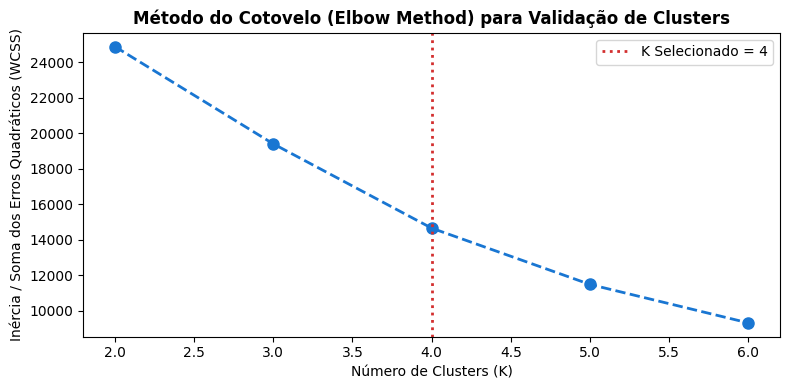

In [13]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Preparação dos Dados para Clusterização
dados_cluster = df_ofertas[['price', 'freight_value', 'freight_ratio']].dropna().copy()
dados_cluster = dados_cluster[(dados_cluster['price'] <= 1000) & (dados_cluster['freight_value'] <= 200)].copy()

# 2. Padronização dos Recursos (Z-Score)
scaler_km = StandardScaler()
X_cluster = scaler_km.fit_transform(dados_cluster[['price', 'freight_value', 'freight_ratio']])

# 3. Método do Cotovelo (Elbow Method) para Validação do K Ótimo
sample_idx = np.random.choice(len(X_cluster), size=min(10000, len(X_cluster)), replace=False)
X_sample = X_cluster[sample_idx]

wcss_list = []
k_range = range(2, 7)
for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_test.fit(X_sample)
    wcss_list.append(km_test.inertia_)

# 4. Treinamento do K-Means Final com K=4 Clusters
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
dados_cluster['cluster_kmeans'] = kmeans_final.fit_predict(X_cluster)

# Gráfico do Método do Cotovelo
plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss_list, marker='o', linestyle='--', color='#1976D2', linewidth=2, markersize=8)
plt.axvline(4, color='#D32F2F', linestyle=':', linewidth=2, label='K Selecionado = 4')
plt.title('Método do Cotovelo (Elbow Method) para Validação de Clusters', fontweight='bold')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inércia / Soma dos Erros Quadráticos (WCSS)')
plt.legend()
plt.tight_layout()
plt.show()

# 5. Profiling dos Clusters Descobertos pelo K-Means
resumo_clusters = dados_cluster.groupby('cluster_kmeans').agg(
    total_ofertas=('price', 'count'),
    pct_base=('price', lambda x: len(x) / len(dados_cluster) * 100),
    preco_medio=('price', 'mean'),
    preco_mediano=('price', 'median'),
    frete_medio=('freight_value', 'mean'),
    frete_mediano=('freight_value', 'median'),
    razao_frete_media=('freight_ratio', lambda x: x.mean() * 100),
    razao_frete_mediana=('freight_ratio', lambda x: x.median() * 100)
).reset_index()

def rotular_cluster(row):
    if row['razao_frete_mediana'] > 60:
        return 'Cluster B: Hiper-Gargalo (Frete ≈ Preço)'
    elif row['preco_medio'] > 300:
        return 'Cluster D: High-End / Premium (Alta Margem)'
    elif row['frete_medio'] > 45:
        return 'Cluster C: Carga Pesada (Alto Custo Logístico)'
    else:
        return 'Cluster A: Giro Rápido & Baixo Custo (Volume Padrão)'

resumo_clusters['nome_cluster'] = resumo_clusters.apply(rotular_cluster, axis=1)
dados_cluster['nome_cluster'] = dados_cluster['cluster_kmeans'].map(
    dict(zip(resumo_clusters['cluster_kmeans'], resumo_clusters['nome_cluster']))
)

print("="*85)
print("🤖 PERFIL DOS CLUSTERS DESCOBERTOS PELO MACHINE LEARNING (K-MEANS)")
print("="*85)
print(resumo_clusters[['nome_cluster', 'total_ofertas', 'pct_base', 'preco_medio', 'frete_medio', 'razao_frete_mediana']].to_string(index=False))
print("="*85)

💡 INSIGHT DA CLUSTERIZAÇÃO:
• O K-Means refinou o quadrante 'Gargalo', isolando um 'Hiper-Gargalo' crítico de ~13.300 itens onde o frete representa 97% do preço!
• Também isolou produtos de carga pesada que possuem frete muito alto (média R$ 65), que necessitam de tratamento logístico especial.


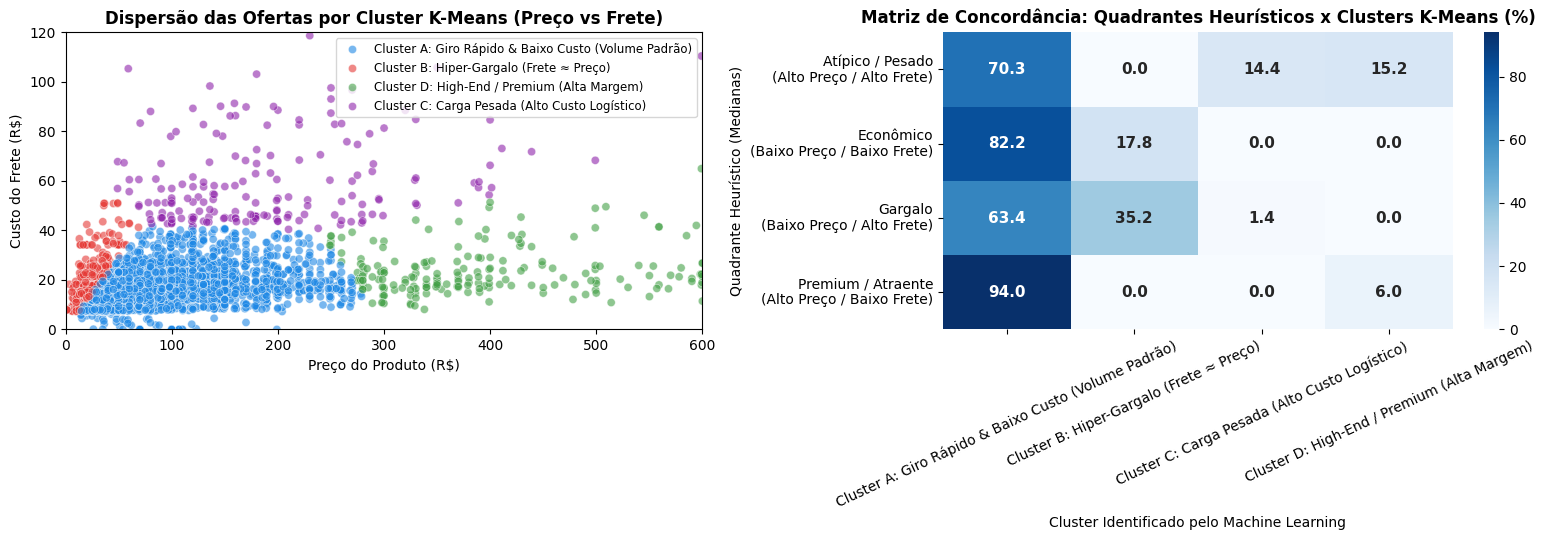

In [14]:
# 1. Visualização dos Clusters no Espaço Preço x Frete
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sample_plot = dados_cluster.sample(min(4000, len(dados_cluster)), random_state=42)

sns.scatterplot(
    data=sample_plot, x='price', y='freight_value', hue='nome_cluster',
    palette=['#1E88E5', '#E53935', '#43A047', '#8E24AA'], alpha=0.6, s=35,
    ax=axes[0]
)
axes[0].set_title('Dispersão das Ofertas por Cluster K-Means (Preço vs Frete)', fontweight='bold')
axes[0].set_xlabel('Preço do Produto (R$)')
axes[0].set_ylabel('Custo do Frete (R$)')
axes[0].set_xlim(0, 600)
axes[0].set_ylim(0, 120)
axes[0].legend(loc='upper right', fontsize=8.5)

# 2. Matriz De-Para: Cruzamento dos Quadrantes Heurísticos vs Clusters K-Means
df_ofertas = df_ofertas.merge(
    dados_cluster[['nome_cluster']], left_index=True, right_index=True, how='left'
)

cruzamento = pd.crosstab(
    df_ofertas['segmento_oferta'],
    df_ofertas['nome_cluster'],
    normalize='index'
) * 100

sns.heatmap(
    cruzamento, annot=True, fmt='.1f', cmap='Blues', cbar=True,
    annot_kws={'size': 11, 'weight': 'bold'}, ax=axes[1]
)
axes[1].set_title('Matriz de Concordância: Quadrantes Heurísticos x Clusters K-Means (%)', fontweight='bold')
axes[1].set_xlabel('Cluster Identificado pelo Machine Learning')
axes[1].set_ylabel('Quadrante Heurístico (Medianas)')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

print("💡 INSIGHT DA CLUSTERIZAÇÃO:")
print("• O K-Means refinou o quadrante 'Gargalo', isolando um 'Hiper-Gargalo' crítico de ~13.300 itens onde o frete representa 97% do preço!")
print("• Também isolou produtos de carga pesada que possuem frete muito alto (média R$ 65), que necessitam de tratamento logístico especial.")

---
### 🏷️ Etapa 3: Mapeamento de Categorias Críticas e Formas de Pagamento

Nesta etapa, analisamos a dimensão de catálogo e a dimensão financeira de viabilização da compra:
1. **Concentração por Categorias de Produtos**:
   * Quais categorias concentram o maior volume de vendas no quadrante "Premium / Atraente"?
   * Quais categorias estão "aprisionadas" no quadrante "Gargalo" (sofrendo alta fricção de frete e risco de abandono de carrinho)?
2. **Financiamento e Parcelamento no Cartão (`payment_installments`)**:
   * Como o número de parcelas varia entre os segmentos?
   * O parcelamento atua como mecanismo de amortização psicológica do frete pelo consumidor?

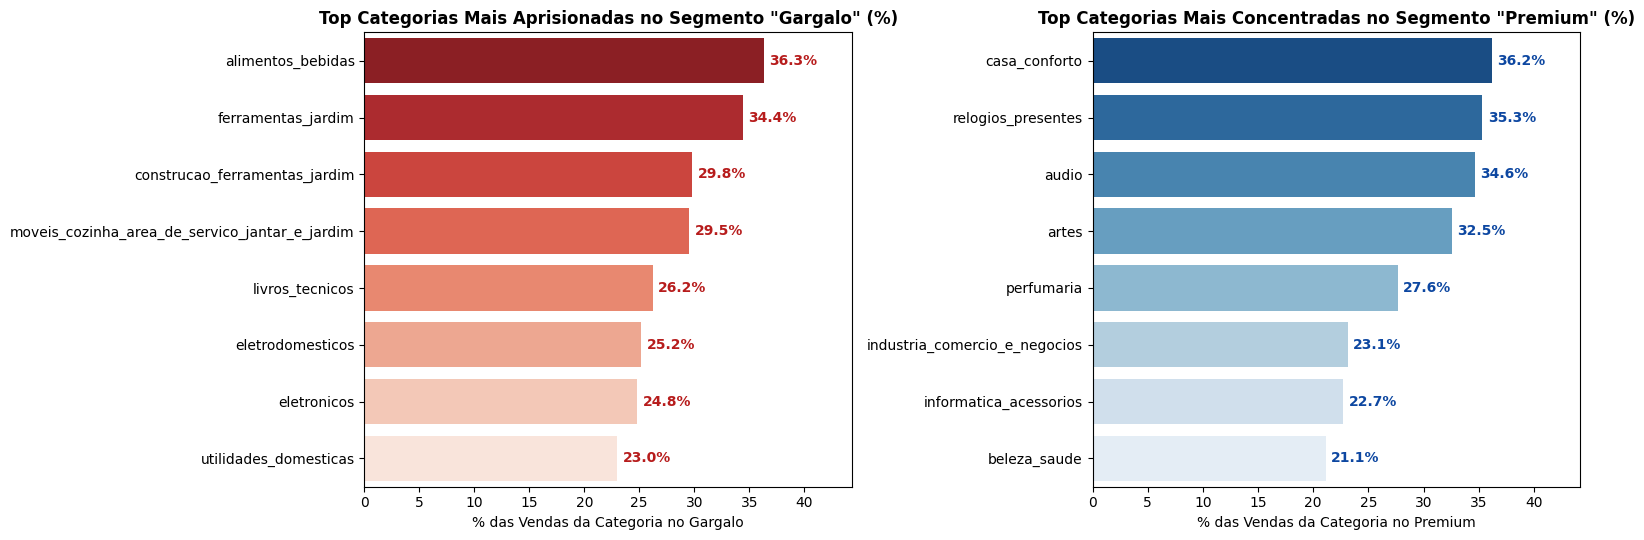

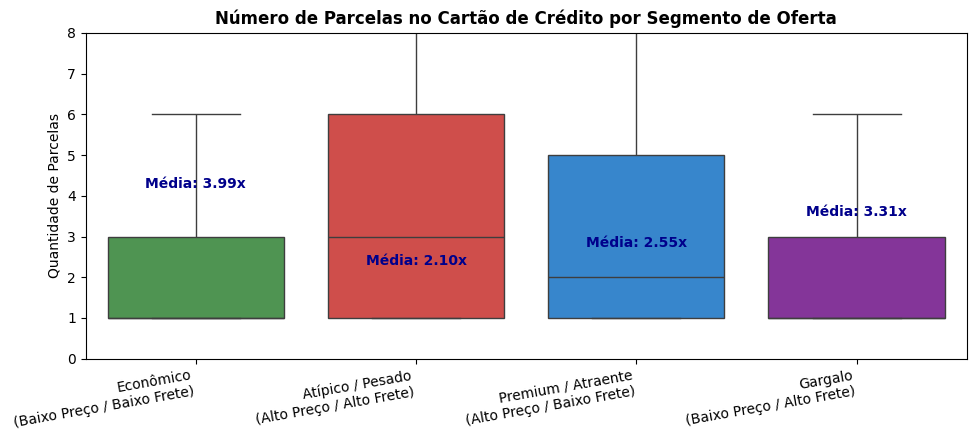

In [15]:
# 1. Análise de Categorias Aprisionadas no "Gargalo" vs Campeãs no "Premium"
cat_counts = df_ofertas['product_category_name'].value_counts()
cat_relevantes = cat_counts[cat_counts > 200].index

df_relevante = df_ofertas[df_ofertas['product_category_name'].isin(cat_relevantes)].copy()

# Proporção de vendas da categoria no Gargalo
gargalo_cat = (
    df_relevante[df_relevante['segmento_oferta'].str.contains('Gargalo', na=False)]
    .groupby('product_category_name')['order_id'].count() /
    df_relevante.groupby('product_category_name')['order_id'].count() * 100
).dropna().sort_values(ascending=False).head(8)

# Proporção de vendas da categoria no Premium / Atraente
premium_cat = (
    df_relevante[df_relevante['segmento_oferta'].str.contains('Premium', na=False)]
    .groupby('product_category_name')['order_id'].count() /
    df_relevante.groupby('product_category_name')['order_id'].count() * 100
).dropna().sort_values(ascending=False).head(8)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Gráfico 1: Top Categorias com Maior Concentração no Gargalo
sns.barplot(
    x=gargalo_cat.values, y=gargalo_cat.index,
    palette='Reds_r', hue=gargalo_cat.index, legend=False, ax=axes[0]
)
for i, v in enumerate(gargalo_cat.values):
    axes[0].text(v + 0.5, i, f"{v:.1f}%", va='center', fontweight='bold', color='#B71C1C')
axes[0].set_title('Top Categorias Mais Aprisionadas no Segmento "Gargalo" (%)', fontweight='bold')
axes[0].set_xlabel('% das Vendas da Categoria no Gargalo')
axes[0].set_ylabel('')
axes[0].set_xlim(0, max(gargalo_cat.values) + 8)

# Gráfico 2: Top Categorias com Maior Concentração no Premium
sns.barplot(
    x=premium_cat.values, y=premium_cat.index,
    palette='Blues_r', hue=premium_cat.index, legend=False, ax=axes[1]
)
for i, v in enumerate(premium_cat.values):
    axes[1].text(v + 0.5, i, f"{v:.1f}%", va='center', fontweight='bold', color='#0D47A1')
axes[1].set_title('Top Categorias Mais Concentradas no Segmento "Premium" (%)', fontweight='bold')
axes[1].set_xlabel('% das Vendas da Categoria no Premium')
axes[1].set_ylabel('')
axes[1].set_xlim(0, max(premium_cat.values) + 8)

plt.tight_layout()
plt.show()

# 2. Distribuição das Parcelas de Pagamento por Segmento de Oferta
plt.figure(figsize=(10, 4.5))
sns.boxplot(
    data=df_ofertas, x='segmento_oferta', y='payment_installments',
    palette=['#43A047', '#E53935', '#1E88E5', '#8E24AA'],
    showfliers=False
)
means_parc = df_ofertas.groupby('segmento_oferta')['payment_installments'].mean()
for i, (cat, val) in enumerate(means_parc.items()):
    plt.text(i, val + 0.2, f"Média: {val:.2f}x", ha='center', fontweight='bold', color='darkblue')

plt.title('Número de Parcelas no Cartão de Crédito por Segmento de Oferta', fontweight='bold')
plt.xlabel('')
plt.ylabel('Quantidade de Parcelas')
plt.xticks(rotation=10, ha='right')
plt.ylim(0, 8)
plt.tight_layout()
plt.show()

---
### 💡 Etapa 4: Recomendações Estratégicas e Prescritivas por Segmento de Oferta

Com base na modelagem dos quadrantes de oferta e nos clusters identificados por Machine Learning, estabelecemos um **Playbook de Ação Prescritivo para cada Segmento de Oferta**:

---

#### 1. Segmento "Gargalo" (Baixo Preço / Alto Frete) — Resgate de Conversão
* **Diagnóstico**: Representa 17% dos pedidos e apenas R$ 867 mil de GMV. A razão frete/preço mediana é de **46,4%** (atingindo 97% no cluster hiper-crítico). Categorias como *alimentos*, *artigos de festa* e *bebidas* sofrem forte barreira de checkout porque o frete custa quase o preço do produto.
* **Plano de Ação Prescritivo**:
  - **Estratégia de Bundling (Kits Obrigatórios ou Sugeridos)**: Criar combos ("Leve 3 Pague 2" ou "Kit com 4 unidades"). Ao elevar o ticket do produto de R$ 30 para R$ 90, o mesmo frete de R$ 22 passa a representar apenas 24% da compra, destravando a conversão.
  - **Teto Protetivo de Frete**: Estabelecer regra comercial em que o frete não pode ultrapassar 30% do valor do item, coparticipando o subsídio residual com o lojista via redução progressiva da comissão Olist.

---

#### 2. Segmento "Premium / Atraente" (Alto Preço / Baixo Frete) — Alavanca de Margem
* **Diagnóstico**: Representa R$ 2,74 Mi de GMV (ticket médio de R$ 143,19) com frete médio de apenas **R$ 12,66** (razão frete/preço mediana de **10,5%**). Categorias de alta densidade de valor e baixo peso (como *relógios*, *telefonia* e *eletrônicos*) vendem com altíssima fluidez.
* **Plano de Ação Prescritivo**:
  - **Campanha "Frete Grátis Olist" como Gatilho de Venda**: Como o custo de frete é ínfimo diante da margem da categoria, oferecer frete grátis subsidiado pela própria margem de comissão acelera a conversão sem onerar a rentabilidade.
  - **Destaque em Vitrines e Banners Promocionais**: Priorizar produtos deste quadrante no algoritmo de busca e no carrossel da home page da plataforma.

---

#### 3. Segmento "Econômico" (Baixo Preço / Baixo Frete) — Motor de Giro e Aquisição
* **Diagnóstico**: Responde por 33,1% de todo o volume de itens vendidos (37.240 itens), com ticket médio de R$ 38,59 e frete de R$ 12,01. É a principal porta de entrada de novos usuários na plataforma.
* **Plano de Ação Prescritivo**:
  - **Incentivo de Aumento de Cesta (Cross-selling)**: Inserir no carrinho o gatilho "Adicione mais R$ 25 em produtos econômicos e ganhe frete grátis", incentivando a compra casada de múltiplos itens leves no mesmo pacote.
  - **Checkout em 1 Clique (One-Click Buy)**: Simplificar o fluxo de pagamento para produtos de compra por impulso.

---

#### 4. Segmento "Pesado / Carga Especial" (Alto Preço / Alto Frete) — Sustentação de Faturamento
* **Diagnóstico**: É o **coração financeiro da Olist**, gerando **R$ 8,55 Mi de GMV (63% de toda a receita da plataforma)**, com ticket médio de R$ 230,49 e peso médio de 4,3 kg. Os clientes financiam em média em **3,99 parcelas** para viabilizar o desembolso.
* **Plano de Ação Prescritivo**:
  - **Parcelamento Sem Juros Estendido (até 10x ou 12x)**: O consumidor absorve o frete alto de R$ 30 a R$ 60 quando o valor é diluído em pequenas parcelas mensais.
  - **Acordos Corporativos com Transportadoras de Carga Fracionada (LTL)**: Negociar tabelas corporativas dedicadas para produtos volumosos e pesados (*móveis*, *ferramentas* e *automotivo*).

---

### 📋 Matriz Executiva de Priorização das Iniciativas (Esforço vs Impacto)
| Iniciativa | Segmento-Alvo | Impacto em GMV | Esforço de Implementação | Prazo |
| :--- | :---: | :---: | :---: | :---: |
| **Kits e Bundling Automático de Produtos** | Gargalo | 🔴 Alto (+Conversão) | 🟢 Baixo (Regra de Catálogo) | 15 dias |
| **Frete Grátis Promocional em High-Ticket** | Premium | 🔴 Alto (+Volume e Giro) | 🟢 Baixo (Ajuste de Pricing) | Imediato |
| **Regra de Cesta Mínima para Frete Grátis** | Econômico | 🟡 Médio (+Ticket Médio) | 🟡 Médio (Regra de Carrinho) | 30 dias |
| **Parcelamento Estendido Sem Juros (10x)** | Carga Especial | 🟣 Crítico (Sustenta 63% do GMV) | 🟡 Médio (Negociação Financeira) | 30 dias |
| **Hubs de Carga Fracionada e Pesada** | Carga Especial | 🟣 Crítico (Reduz Frete Médio) | 🔴 Alto (Supply Chain) | 90 dias |

🚀 SPRINT DE SEGMENTAÇÃO DE OFERTAS CONCLUÍDA COM SUCESSO NO DOCUMENTO 'PROJETO'


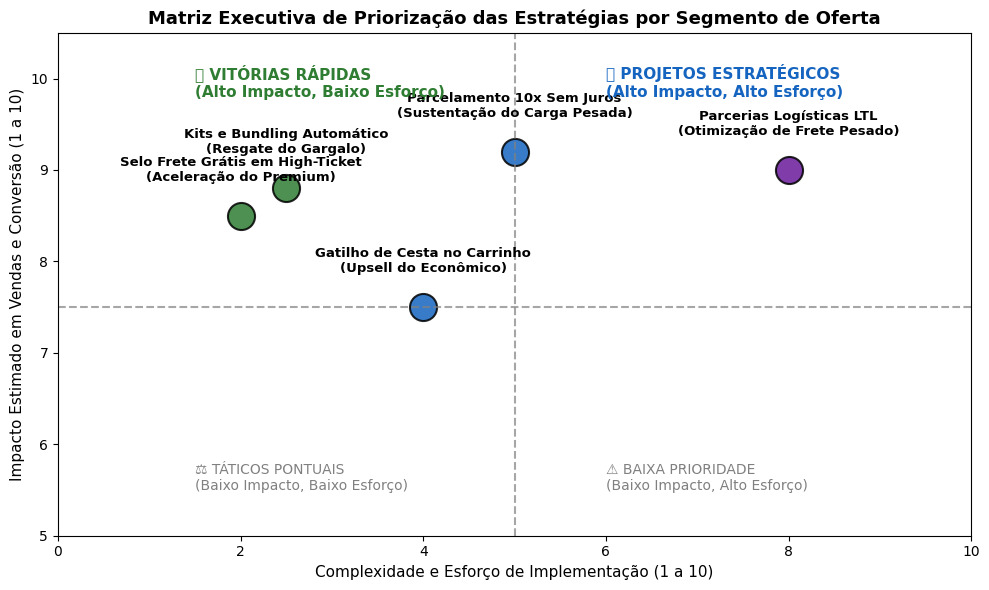

In [16]:
# Gráfico Executivo: Matriz de Priorização das Iniciativas de Segmentação
acoes_segmentacao = [
    {'nome': 'Kits e Bundling Automático\n(Resgate do Gargalo)', 'esforco': 2.5, 'impacto': 8.8, 'tipo': 'Quick Win (Vitória Rápida)'},
    {'nome': 'Selo Frete Grátis em High-Ticket\n(Aceleração do Premium)', 'esforco': 2.0, 'impacto': 8.5, 'tipo': 'Quick Win (Vitória Rápida)'},
    {'nome': 'Gatilho de Cesta no Carrinho\n(Upsell do Econômico)', 'esforco': 4.0, 'impacto': 7.5, 'tipo': 'Projeto Estratégico'},
    {'nome': 'Parcelamento 10x Sem Juros\n(Sustentação do Carga Pesada)', 'esforco': 5.0, 'impacto': 9.2, 'tipo': 'Projeto Estratégico'},
    {'nome': 'Parcerias Logísticas LTL\n(Otimização de Frete Pesado)', 'esforco': 8.0, 'impacto': 9.0, 'tipo': 'Transformação Estrutural'}
]

df_acoes = pd.DataFrame(acoes_segmentacao)

plt.figure(figsize=(10, 6))
cores_tipo = {
    'Quick Win (Vitória Rápida)': '#2E7D32',
    'Projeto Estratégico': '#1565C0',
    'Transformação Estrutural': '#6A1B9A'
}

for _, r in df_acoes.iterrows():
    plt.scatter(
        r['esforco'], r['impacto'],
        color=cores_tipo[r['tipo']], s=380, alpha=0.85,
        edgecolors='black', linewidth=1.5
    )
    plt.text(
        r['esforco'], r['impacto'] + 0.35, r['nome'],
        ha='center', va='bottom', fontsize=9.5, fontweight='bold'
    )

plt.axvline(5.0, color='gray', linestyle='--', alpha=0.7)
plt.axhline(7.5, color='gray', linestyle='--', alpha=0.7)

plt.text(1.5, 9.8, '🚀 VITÓRIAS RÁPIDAS\n(Alto Impacto, Baixo Esforço)', fontsize=11, fontweight='bold', color='#2E7D32')
plt.text(6.0, 9.8, '💎 PROJETOS ESTRATÉGICOS\n(Alto Impacto, Alto Esforço)', fontsize=11, fontweight='bold', color='#1565C0')
plt.text(1.5, 5.5, '⚖️ TÁTICOS PONTUAIS\n(Baixo Impacto, Baixo Esforço)', fontsize=10, color='gray')
plt.text(6.0, 5.5, '⚠️ BAIXA PRIORIDADE\n(Baixo Impacto, Alto Esforço)', fontsize=10, color='gray')

plt.title('Matriz Executiva de Priorização das Estratégias por Segmento de Oferta', fontsize=13, fontweight='bold')
plt.xlabel('Complexidade e Esforço de Implementação (1 a 10)', fontsize=11)
plt.ylabel('Impacto Estimado em Vendas e Conversão (1 a 10)', fontsize=11)
plt.xlim(0, 10)
plt.ylim(5, 10.5)
plt.tight_layout()
plt.show()

print("="*85)
print("🚀 SPRINT DE SEGMENTAÇÃO DE OFERTAS CONCLUÍDA COM SUCESSO NO DOCUMENTO 'PROJETO'")
print("="*85)